# Simulaciones con un modelo global de complejidad media

Se generaron cuatro simulaciones como prueba de concepto de la respuesta atmosférica a una anomalía ENSO (usando **SpeedyWeather** y el lenguaje **Julia**)

El objetivo de estas simulaciones es  mostrar experimentos numéricos que muestre los efectos en la atmósfera de cambios en la perturbación de $SST$:

$$
\mathrm{CTRL}:\quad SST = SST_{clim}
$$
$$
\mathrm{EXP}:\quad SST = SST_{clim} + \Delta SST_{ENSO}
$$

y analizar posteriormente

$$
\Delta X = X_{EXP}-X_{CTRL}.
$$

La pregunta que buscamos responder es:

> **¿Cómo responde la atmósfera tropical y global cuando imponemos un calentamiento/enfriamiento idealizado en el Pacífico ecuatorial?**

El modelo atmósferico Speedy se corrió con la **SST preescrita** durante todo el periodo de simulación. Este tipo de simulaciones permite estudiar lo siguiente:

$$
SST' \rightarrow \text{convección}' \rightarrow \text{circulación atmosférica}'.
$$

**Es importante mencionar que esto no es una simulación completa de ENSO.** Ya que el océano no responde dinámicamente al viento, por lo que no podremos ver:

- ondas "Kelvin" y "Rossby" oceánicas generadas por el viento;
- evolución de la termoclina;
- crecimiento espontáneo de ENSO.

Por lo tanto, podemos ver la respuesta atmosférica inducida por el **forzamiento** impuesto en la SST.

> Revisar: **https://github.com/SpeedyWeather**

# Análisis de experimentos ENSO

Se generaron cuatro distintas simulaciones con una duración de *50 años* cada una:

- **CONTROL:** Una climatología de SST
- **NINO_CENTRAL:** Una anomalía positiva ($SST'^+$) gausiana en el centro del Pacífico
- **NINO_EAST:** Una anomalía positiva ($SST'^+$) gausiana en el Pacífico este.
- **NINA:**  Una anomalía negativa ($SST'^-$) gausiana en el Pacífico este.
mediante

$$
\Delta X=\overline{X}_{EXP}-\overline{X}_{CTRL}.
$$
La secuencia física que buscamos es

$$
SST' \rightarrow P' \rightarrow p' \rightarrow (u',v') \rightarrow
\text{respuesta tropical y extratropical}.
$$
***Nota:*** La SST está prescrita, por lo tanto, estos experimentos aíslan la respuesta atmosférica y **no** simulan ENSO acoplado.

# Librerías

In [1]:
#Cargamos librerías necesarias
#I/O
from pathlib import Path
import xarray as xr

#Procesamiento numérico
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

#Visualización
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Definimos rutas

Para esta comparación utilizaremos los experimentos:

- CONTROL definido como `CTRL` a lo largo del notebook
- NINO_CENTRAL definido como `EXP` a lo largo del notebook  

In [2]:
# Definimos rutas de los archivos
FCTRL="./CTRL.nc"  #Simulación Control
FEXP="./N_CENTRAL.nc" #anomalía positiva en central Pac

# Definimos años de 'spinup', área a analizar y salto de vectores
SPINUP_YEARS = 2  #Años de 'estabilización' de las sims 
TROP_LAT = (-20, 20) #Cinturón latitudinal tropical
EQ_LAT = (-5, 5) #Cinturón latitudinal alrededor del ecuador
QUIVER_SKIP = 3 #Saltos para las gráficas de vectores de viento

In [3]:
#Examinamos el archivo CTRL
with xr.open_dataset(FCTRL) as ds:
    for v in ds.data_vars:
        print(f"{v:20s}", ds[v].dims, ds[v].attrs.get("units",""))

/home/jair/miniconda3/envs/oceanography/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


rain_conv            ('time', 'lat', 'lon') mm
rain_cond            ('time', 'lat', 'lon') mm
temp                 ('time', 'layer', 'lat', 'lon') degC
mslp                 ('time', 'lat', 'lon') hPa
vor                  ('time', 'layer', 'lat', 'lon') s^-1
v                    ('time', 'layer', 'lat', 'lon') m/s
cloud_cover          ('time', 'lat', 'lon') 1
div                  ('time', 'layer', 'lat', 'lon') s^-1
u                    ('time', 'layer', 'lat', 'lon') m/s
snow_conv            ('time', 'lat', 'lon') mm
cloud_top            ('time', 'lat', 'lon') m
humid                ('time', 'layer', 'lat', 'lon') kg/kg
sst                  ('time', 'lat', 'lon') degC
snow_cond            ('time', 'lat', 'lon') mm
rain_conv_rate       ('time', 'lat', 'lon') mm/hr
rain_cond_rate       ('time', 'lat', 'lon') mm/hr
snow_conv_rate       ('time', 'lat', 'lon') mm/hr
snow_cond_rate       ('time', 'lat', 'lon') mm/hr


------------------------------------------------------------------------
Una inspección de las variables nos da que tenemos 4 dimensiones distintas:

- time
- lat
- lon
- layers

`layers` es una dimensión para niveles en la vertical. Es necesario explorarla para saber qué niveles tenemos, ya que el modelo utiliza la coordenada vertical sigma ($\sigma$) definida como:

$$
\sigma = \frac{p}{p_s}
$$
------------------------------------------------------------------------

In [4]:
# Examinamos los niveles verticales
# del archivo CTRL
with xr.open_dataset(FCTRL) as ds:
    print("\nlayer =",ds['layer'].values)


layer = [0.0625 0.1875 0.3125 0.4375 0.5625 0.6875 0.8125 0.9375]


------------------------------------------------------------------------
Esta inspección permite ver que la dimensión `layer` contiene coordenadas $\sigma$ con centros:

$$
0.0625,0.1875,0.3125,0.4375,0.5625,0.6875,0.8125,0.9375
$$

Por lo tanto, usaremos los siguientes niveles:

- **nivel bajo:** $\sigma=0.8125$, aproximadamente 800 hPa si $p_s\approx1000$ hPa;
- **nivel alto:** $\sigma=0.1875$, aproximadamente 200 hPa.
------------------------------------------------------------------------
Las salidas tienen:

- longitud $0–356.25^\circ E$;
- latitud ordenada originalmente de norte a sur;
- 8 niveles sigma.

Ordenamos `lat` de sur a norte únicamente para facilitar las selecciones `slice(-20,20)`.

------------------------------------------------------------------------

In [5]:
#Deinimos los dos niveles del modelo a utilizar
LOW_SIGMA = 0.8125
HIGH_SIGMA = 0.1875

# Funciones

In [6]:
#Definimos una función que nos permita cargar y acomodar 
# de acuerdo a la latitud

def open_speedy(path):
    ds = xr.open_dataset(path)
    ds = ds.sortby("lat")
    return ds

#Para obtener el promedio de área es necesario hacerlo pesado por 
#la latitud

def area_prom(da, lat_bounds=None, lon_bounds=None):
    out = da

    if lat_bounds is not None:
        out = out.sel(lat=slice(lat_bounds[0], lat_bounds[1]))

    if lon_bounds is not None:
        lon0, lon1 = lon_bounds

        if lon0 <= lon1:
            out = out.sel(lon=slice(lon0, lon1))
        else:
            a = out.sel(lon=slice(lon0, 360))
            b = out.sel(lon=slice(0, lon1))
            out = xr.concat([a, b], dim="lon")

    weights = np.cos(np.deg2rad(out.lat))
    dims = [d for d in ["lat", "lon"] if d in out.dims]

    return out.weighted(weights).mean(dims)

#Esta función solamente hace promedios latitudinales 
# dejando las longitudes
def latitud_prom(da, lat_bounds):

    out = da.sel(
        lat=slice(
            lat_bounds[0],
            lat_bounds[1]
        )
    )

    weights = np.cos(
        np.deg2rad(out.lat)
    )

    return out.weighted(weights).mean("lat")

#Calcula el promedio anual
def anual_prom(da):
    return da.resample(time="YS").mean("time")

#Esta función es necesaria para recortar los años que se definieron 
# para que Speedy se estabilizara
def remov_spinup(ds, years):
    start = pd.Timestamp(ds.time.values[0])
    new_start = start + pd.DateOffset(years=years)
    return ds.sel(time=slice(new_start, None))

#Calcula la tasa total de precipitación liquida (lluvia)
def rain_rate(ds):
    return ds["rain_conv_rate"] + ds["rain_cond_rate"]


# Visualizamos los promedios anuales en el cinturón tropical para evaluar si el modelo llego a un equilibrio

In [7]:
# Creamos una pequeña función que hará cálculos para distintas vars
def diag_inicial(ds):

    precip = anual_prom(
        area_prom(
            rain_rate(ds),
            lat_bounds=TROP_LAT
        )
    )

    temp_low = anual_prom(
        area_prom(
            ds["temp"].sel(layer=LOW_SIGMA),
            lat_bounds=TROP_LAT
        )
    )

    mslp = anual_prom(
        area_prom(
            ds["mslp"],
            lat_bounds=TROP_LAT
        )
    )

    return {
        "Precipitación tropical": precip,
        "Temperatura tropical, sigma=0.8125": temp_low,
        "MSLP tropical": mslp,
    }

In [8]:
#Cargamos los archivos a comparar

ctrl = open_speedy(FCTRL) #experimento CONTROL
exp = open_speedy(FEXP) #experimento NINO_CENTRAL

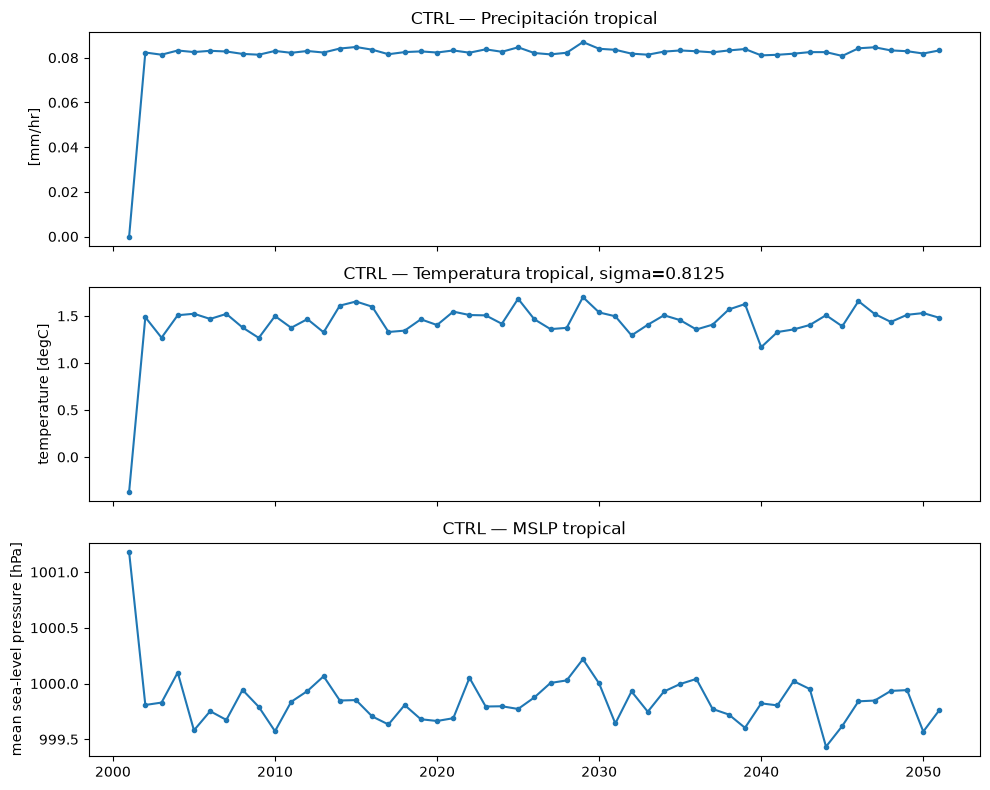

In [9]:
# Generamos las gráficas de las series de tiempo de los promedios
# en el cinturón tropical para el CTRL
t_series = diag_inicial(ctrl)
XP='CTRL'

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 8),
    sharex=True
)

for ax, (label, s) in zip(axes, t_series.items()):
    s.plot(ax=ax, marker="o", ms=3)
    ax.set_title(f"{XP} — {label}")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

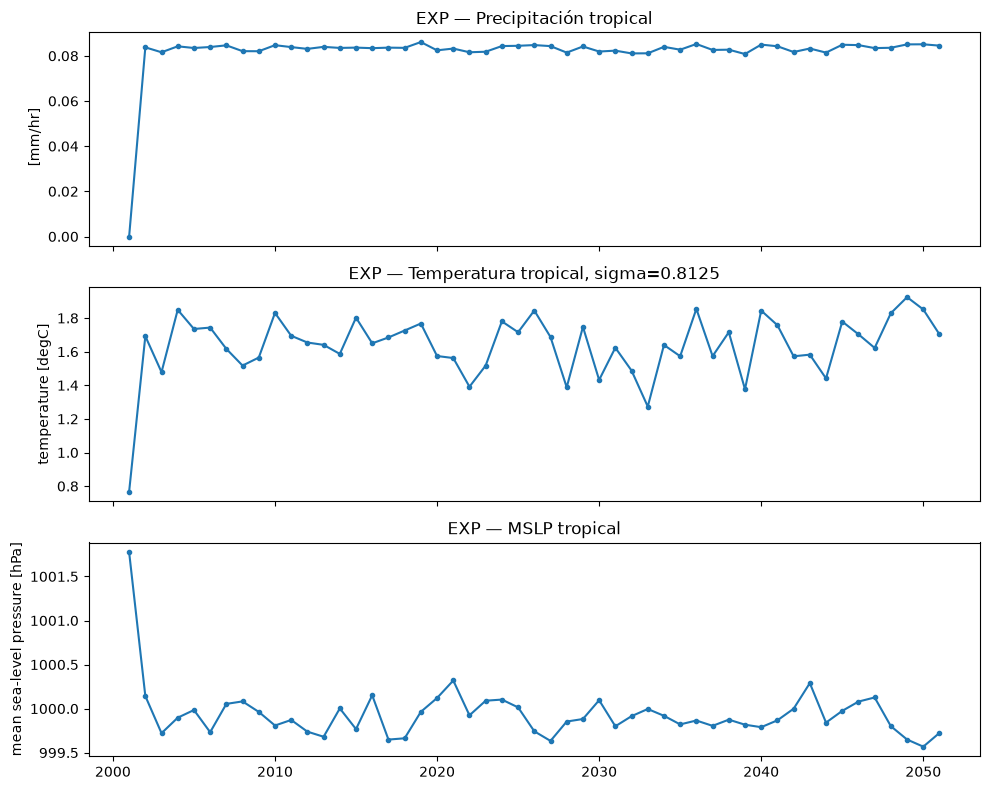

In [10]:
# Generamos las gráficas de las series de tiempo de los promedios
# en el cinturón tropical para el EXP
t_series = diag_inicial(exp)
XP='EXP'
fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 8),
    sharex=True
)

for ax, (label, s) in zip(axes, t_series.items()):
    s.plot(ax=ax, marker="o", ms=3)
    ax.set_title(f"{XP} — {label}")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

> **Nota:** buscamos que los promedios anuales dejen de mostrar una deriva sistemática. El objetivo es separar el ajuste inicial del régimen estadístico.

# Eliminamos el spin-up

Los primeros dos años que se ven claramente que tienen otras caraterísticas estadísticas que todo lo demás de las series de tiempo de **CTRL** y **EXP**

In [11]:
tctrl = remov_spinup(ctrl, SPINUP_YEARS)
texp  = remov_spinup(exp, SPINUP_YEARS)
print ('CTRL',str(ctrl.time.values[0])[:10],"->",
       str(ctrl.time.values[-1])[:10], 'con SPINUP')
print ('CTRL',str(tctrl.time.values[0])[:10],"->",
       str(tctrl.time.values[-1])[:10], 'sin SPINUP')
print ('EXP',str(exp.time.values[0])[:10],"->",
       str(exp.time.values[-1])[:10], 'con SPINUP')
print ('EXP',str(texp.time.values[0])[:10],"->",
       str(texp.time.values[-1])[:10], 'sin SPINUP')

CTRL 2001-12-31 -> 2051-12-09 con SPINUP
CTRL 2004-01-20 -> 2051-12-09 sin SPINUP
EXP 2001-12-31 -> 2051-12-09 con SPINUP
EXP 2004-01-20 -> 2051-12-09 sin SPINUP


# Verificación de la perturbación SST

$$
SST'=SST_{EXP}-SST_{CTRL}.
$$

In [12]:
#Generamos una función para crear gráficas de los experimentos
def plot_map(da, title="", symmetric=False, cmap="RdBu_r"):

    fig = plt.figure(figsize=(11, 4.8))

    ax = plt.axes(
        projection=ccrs.PlateCarree(
            central_longitude=180
        )
    )

    kwargs = {
        "ax": ax,
        "transform": ccrs.PlateCarree(),
        "x": "lon",
        "y": "lat",
        "cmap": cmap,
        "add_colorbar": True
    }

    if symmetric:
        vmax = float(
            np.nanpercentile(
                np.abs(da.values),
                98
            )
        )
        kwargs["vmin"] = -vmax
        kwargs["vmax"] = vmax

    da.plot(**kwargs)

    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax.set_global()
    ax.set_title(title)

    plt.tight_layout()
    plt.show()

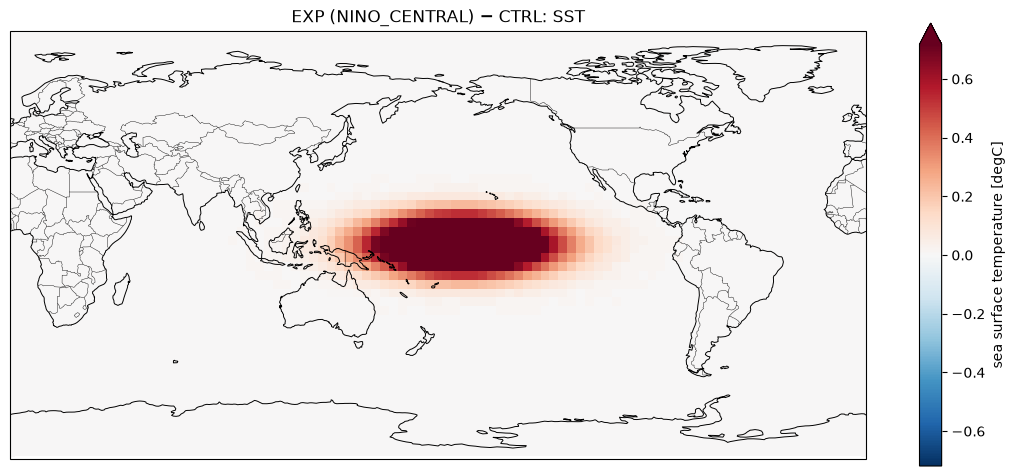

In [13]:
# Calculamos las diferencias en SST del CTRL - EXP

dsst = (
        texp["sst"].mean("time")
        -
        tctrl["sst"].mean("time")
    )

plot_map(
        dsst,
        title=f"EXP (NINO_CENTRAL) − CTRL: SST",
        symmetric=True,
        cmap="RdBu_r"
    )

# Perfil ecuatorial de SST CTRL y EXP

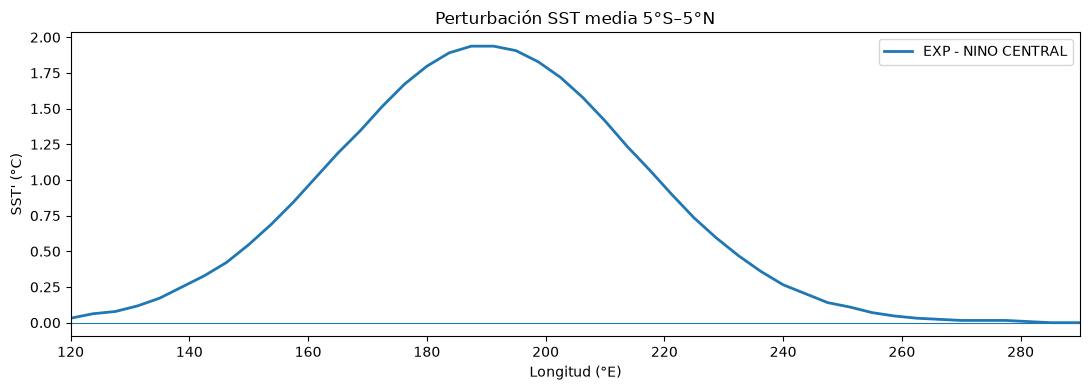

In [14]:
#Gráficamos el promedio alrededor del ecuador de SST para CTRL y EXP
fig, ax = plt.subplots(figsize=(11, 4))

dsst = (
    texp["sst"].mean("time")
    -
    tctrl["sst"].mean("time")
)

eq = latitud_prom(
    dsst,
    lat_bounds=EQ_LAT
)

ax.plot(
    eq.lon,
    eq,
    lw=2,
    label='EXP - NINO CENTRAL'
)

ax.axhline(0, lw=0.8)
ax.set_xlim(120, 290)
ax.set_xlabel("Longitud (°E)")
ax.set_ylabel("SST' (°C)")
ax.set_title("Perturbación SST media 5°S–5°N")
ax.legend()

plt.tight_layout()
plt.show()

# Precipitación

Como ya se mostró en la función arriba, usamos


$$
P = \texttt{rain\_conv\_rate}
+
\texttt{rain\_cond\_rate}.
$$

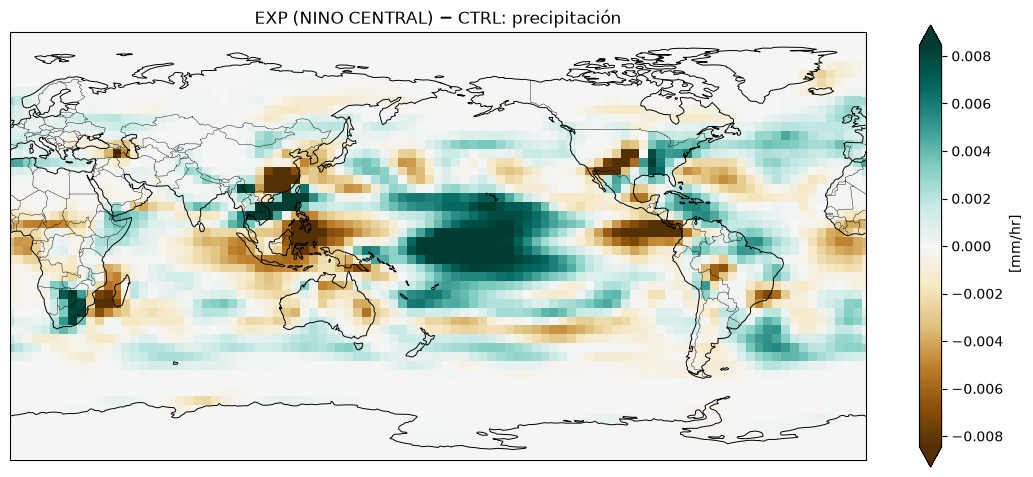

In [15]:
p_ctrl = rain_rate(tctrl)
p_exp  = rain_rate(texp)

dp = p_exp.mean("time") - p_ctrl.mean("time")

plot_map(
        dp,
        title=f"EXP (NINO CENTRAL) − CTRL: precipitación",
        symmetric=True,
        cmap="BrBG"
)



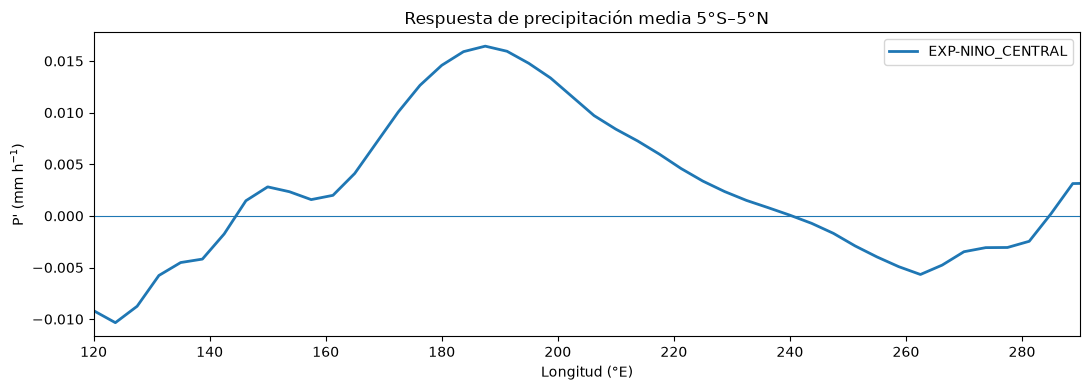

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))

eq = latitud_prom(dp, lat_bounds=EQ_LAT)

ax.plot(eq.lon, eq, lw=2, label='EXP-NINO_CENTRAL')

ax.axhline(0, lw=0.8)
ax.set_xlim(120, 290)
ax.set_xlabel("Longitud (°E)")
ax.set_ylabel("P' (mm h$^{-1}$)")
ax.set_title("Respuesta de precipitación media 5°S–5°N")
ax.legend()

plt.tight_layout()
plt.show()

# Presión reducida a nivel del mar (MSLP)

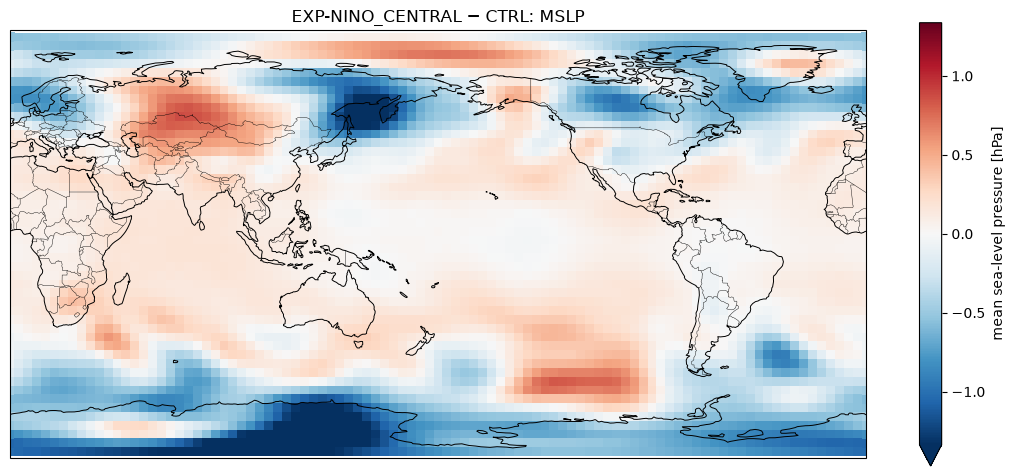

In [17]:
#Calculamos la diferencia del promedio total    
dmslp = texp["mslp"].mean("time") - tctrl["mslp"].mean("time")
plot_map(
        dmslp,
        title=f"EXP-NINO_CENTRAL − CTRL: MSLP",
        symmetric=True,
        cmap="RdBu_r"
)    

# Viento en el nivel bajo: $\sigma = 0.8125 \approx 800 hPa$

In [18]:
#Generamos una función para hacer la gráfica de anomalía de viento
def plot_wind_anomaly(ds_exp, ds_ctrl, sigma, exp_name, label):
    #Promedios a lo largo del tiempo para un nivel sigma CTRL
    u0 = ds_ctrl["u"].sel(layer=sigma).mean("time") 
    v0 = ds_ctrl["v"].sel(layer=sigma).mean("time")

    #Promedios a lo largo del tiempo para un nivel sigma EXP
    u1 = ds_exp["u"].sel(layer=sigma).mean("time")
    v1 = ds_exp["v"].sel(layer=sigma).mean("time")
#Anomalías en U y V
    du = u1-u0
    dv = v1-v0

    speed = np.sqrt(du**2 + dv**2)

    fig = plt.figure(figsize=(12, 5))

    ax = plt.axes(
        projection=ccrs.PlateCarree(
            central_longitude=180
        )
    )

    speed.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        x="lon",
        y="lat",
        cmap="YlGnBu",
        cbar_kwargs={
            "label": "Magnitud del viento anómalo (m s$^{-1}$)"
        }
    )

    ax.quiver(
        du.lon.values[::QUIVER_SKIP],
        du.lat.values[::QUIVER_SKIP],
        du.values[::QUIVER_SKIP, ::QUIVER_SKIP],
        dv.values[::QUIVER_SKIP, ::QUIVER_SKIP],
        transform=ccrs.PlateCarree()
    )

    ax.coastlines(linewidth=0.7)
    ax.set_global()
    ax.set_title(f"{exp_name} − CTRL: viento {label}")

    plt.tight_layout()
    plt.show()

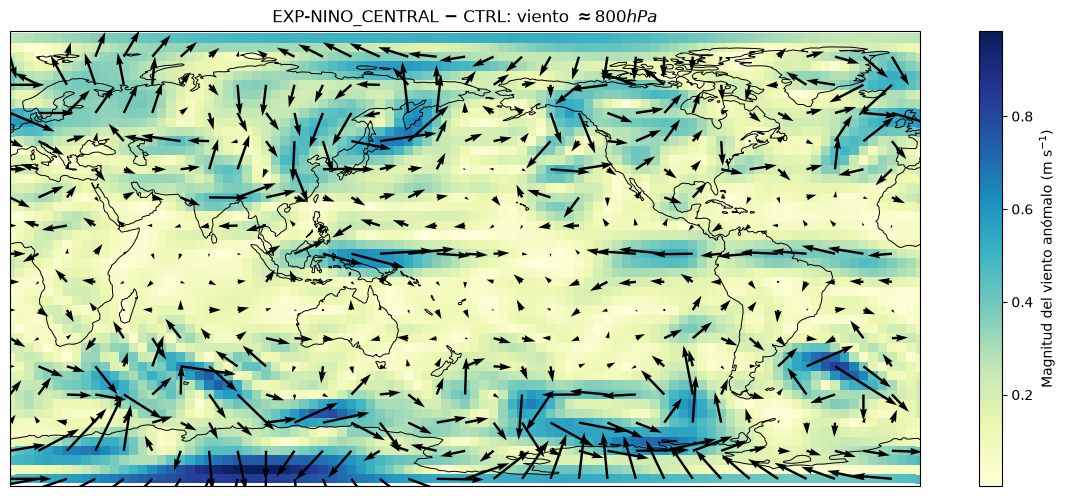

In [19]:
plot_wind_anomaly(
    texp,
    tctrl,
    LOW_SIGMA,
    'EXP-NINO_CENTRAL',
    r"$\approx 800 hPa$"
    )

# Viento en el nivel bajo: $\sigma = 0.1875 \approx 200 hPa$

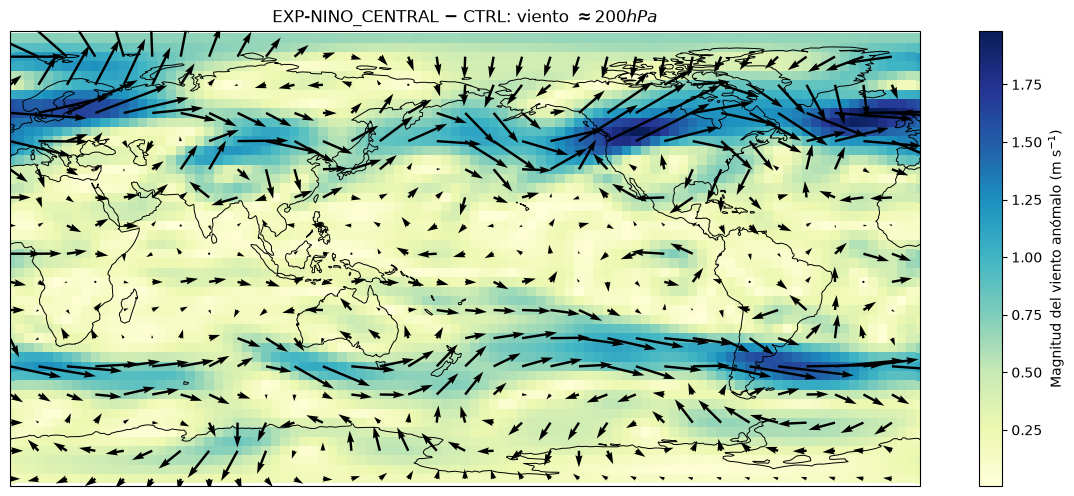

In [20]:
plot_wind_anomaly(
    texp,
    tctrl,
    HIGH_SIGMA,
    'EXP-NINO_CENTRAL',
    r"$\approx 200 hPa$"
    )

# Divergencia 

In [21]:
# Funcion para crear paneles de figuras
def plot_compare_maps(
    da_left,
    da_right,
    title_left,
    title_right,
    suptitle="",
    cmap="YlGnBu",
    symmetric=True,
    robust=True,
    cbar_label=""
):
    # Escala común para ambos paneles
    values = np.concatenate([
        da_left.values.ravel(),
        da_right.values.ravel()
    ])

    values = values[np.isfinite(values)]

    if symmetric:

        if robust:
            vmax = np.nanpercentile(
                np.abs(values),
                98
            )
        else:
            vmax = np.nanmax(
                np.abs(values)
            )

        vmin = -vmax

    else:

        if robust:
            vmin = np.nanpercentile(
                values,
                2
            )

            vmax = np.nanpercentile(
                values,
                98
            )

        else:
            vmin = np.nanmin(values)
            vmax = np.nanmax(values)

    # --------------------------------------------------
    # Figura
    # --------------------------------------------------
    projection = ccrs.PlateCarree(
        central_longitude=180
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 4.8),
        subplot_kw={
            "projection": projection
        }
    )

    # --------------------------------------------------
    # Panel izquierdo
    # --------------------------------------------------
    im = da_left.plot(
        ax=axes[0],
        transform=ccrs.PlateCarree(),
        x="lon",
        y="lat",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )

    axes[0].coastlines(
        linewidth=0.7
    )

    axes[0].add_feature(
        cfeature.BORDERS,
        linewidth=0.3
    )

    axes[0].set_global()
    axes[0].set_title(title_left)

    # --------------------------------------------------
    # Panel derecho
    # --------------------------------------------------
    da_right.plot(
        ax=axes[1],
        transform=ccrs.PlateCarree(),
        x="lon",
        y="lat",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )

    axes[1].coastlines(
        linewidth=0.7
    )

    axes[1].add_feature(
        cfeature.BORDERS,
        linewidth=0.3
    )

    axes[1].set_global()
    axes[1].set_title(title_right)

    # --------------------------------------------------
    # Una sola barra de colores
    # --------------------------------------------------
    cbar = fig.colorbar(
        im,
        ax=axes,
        orientation="horizontal",
        fraction=0.055,
        pad=0.08,
        aspect=45
    )

    cbar.set_label(
        cbar_label
    )

    if suptitle:
        fig.suptitle(
            suptitle,
            fontsize=14,
            y=0.98
        )

    plt.show()

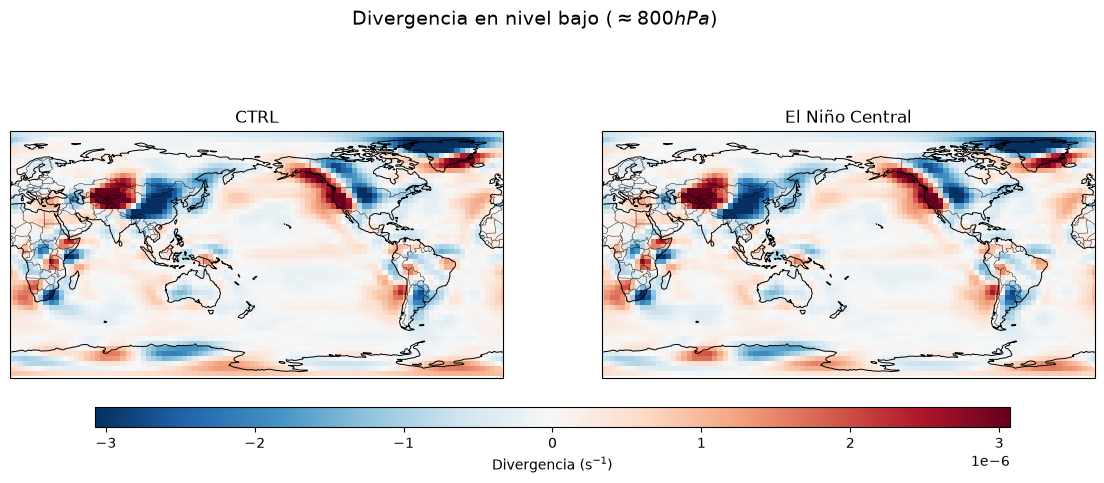

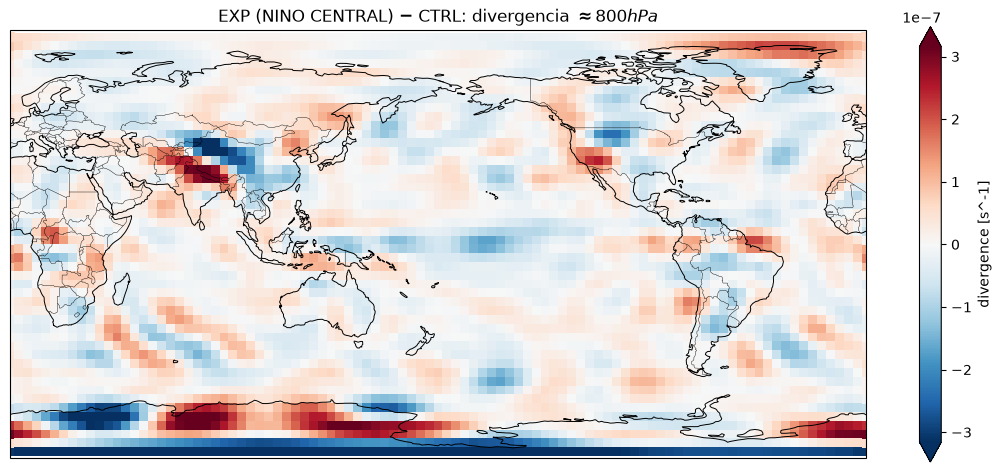

In [22]:
div_ctrl = (
    tctrl["div"]
    .sel(layer=LOW_SIGMA)
    .mean("time")
)

div_exp = (
    texp["div"]
    .sel(layer=LOW_SIGMA)
    .mean("time")
)

plot_compare_maps(
    div_ctrl,
    div_exp,
    title_left="CTRL",
    title_right="El Niño Central",
    suptitle=(
        "Divergencia en nivel bajo "
        r"($\approx 800 hPa$)"
    ),
    cmap="RdBu_r",
    symmetric=True,
    robust=True,
    cbar_label=r"Divergencia (s$^{-1}$)"
)

ddiv = div_exp - div_ctrl
plot_map(
    ddiv,
    title=(
        f"EXP (NINO CENTRAL) − CTRL: divergencia "
        r"$\approx 800 hPa$"
    ),
    symmetric=True,
    cmap="RdBu_r"
    )

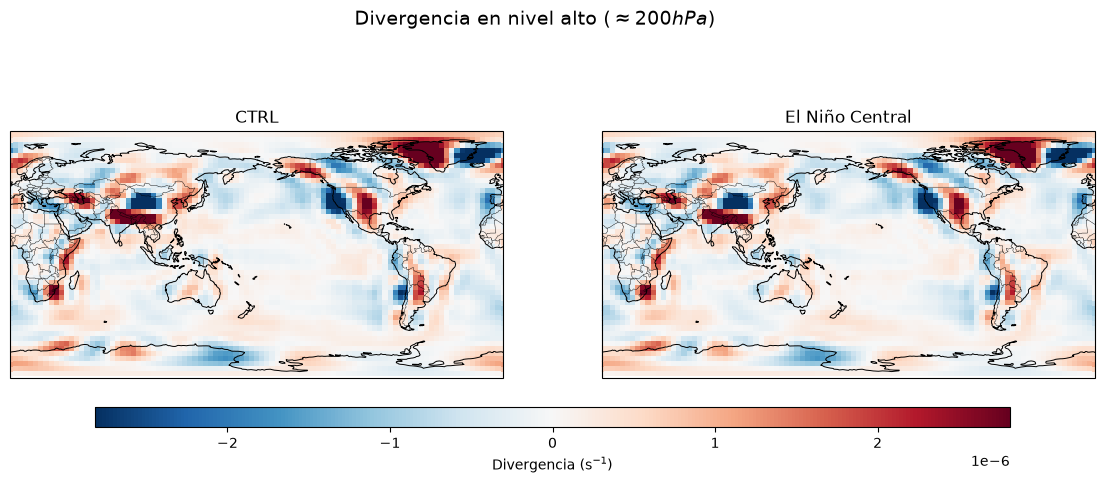

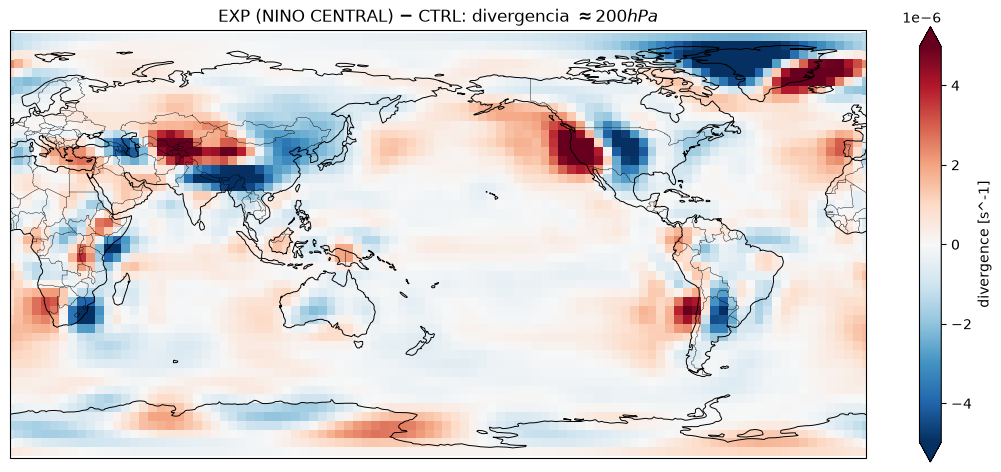

In [23]:
div_ctrl = (
    tctrl["div"]
    .sel(layer=HIGH_SIGMA)
    .mean("time")
)

div_nino_west = (
    texp["div"]
    .sel(layer=HIGH_SIGMA)
    .mean("time")
)

plot_compare_maps(
    div_ctrl,
    div_nino_west,
    title_left="CTRL",
    title_right="El Niño Central",
    suptitle=(
        "Divergencia en nivel alto "
        r"($\approx 200 hPa$)"
    ),
    cmap="RdBu_r",
    symmetric=True,
    robust=True,
    cbar_label=r"Divergencia (s$^{-1}$)"
)

ddiv = div_exp - div_ctrl
plot_map(
    ddiv,
    title=(
        f"EXP (NINO CENTRAL) − CTRL: divergencia "
        r"$\approx 200 hPa$"
    ),
    symmetric=True,
    cmap="RdBu_r"
    )

# Cortes verticales de los promedios ecuatoriales, gráficas 
# $longitud -\sigma$

In [24]:
def secc_ecuatorial(ds_exp, ds_ctrl, var, exp_name, cmap="RdBu_r"):

    diff = (
        ds_exp[var].mean("time")
        -
        ds_ctrl[var].mean("time")
    )

    eq = diff.sel(
        lat=slice(EQ_LAT[0], EQ_LAT[1])
    ).mean("lat")

    fig, ax = plt.subplots(figsize=(11, 5))

    vmax = float(
        np.nanpercentile(
            np.abs(eq.values),
            98
        )
    )

    eq.plot(
        ax=ax,
        x="lon",
        y="layer",
        vmin=-vmax,
        vmax=vmax,
        cmap=cmap
    )

    ax.invert_yaxis()
    ax.set_xlim(120, 290)
    ax.set_ylabel(r"$\sigma$")
    ax.set_title(f"EXP (Niño Central) − CTRL: {var}, media 5°S–5°N")

    plt.tight_layout()
    plt.show()

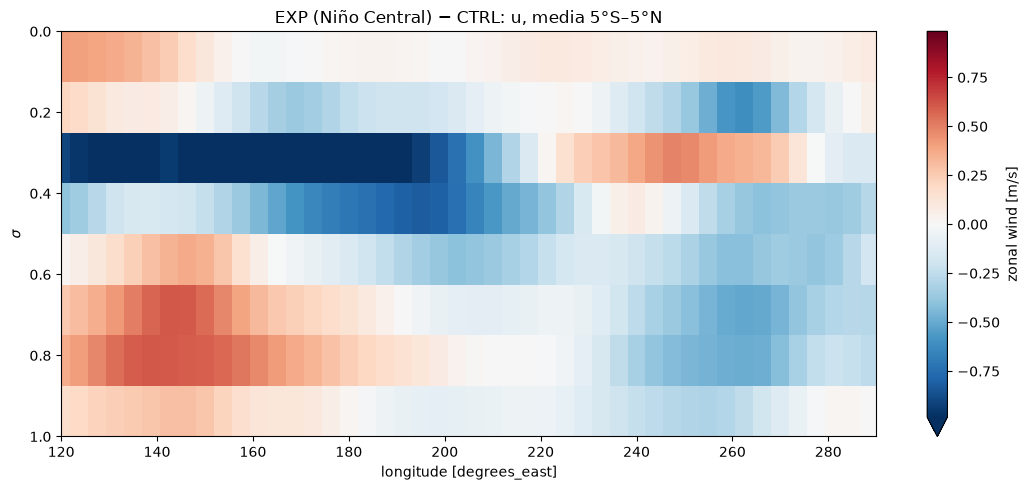

In [25]:
secc_ecuatorial(texp, tctrl, "u", 'EXP (Niño Central)')

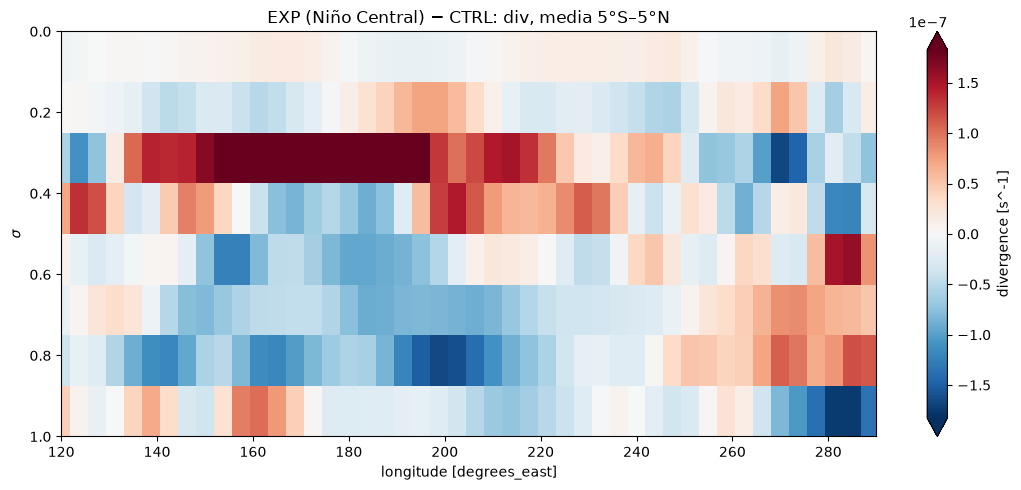

In [26]:
secc_ecuatorial(texp, tctrl, "div", 'EXP (Niño Central)')

# Humedad y temperatura cerca de la superficie
 nivel $\sigma = 0.8125 \approx 800 hPa$

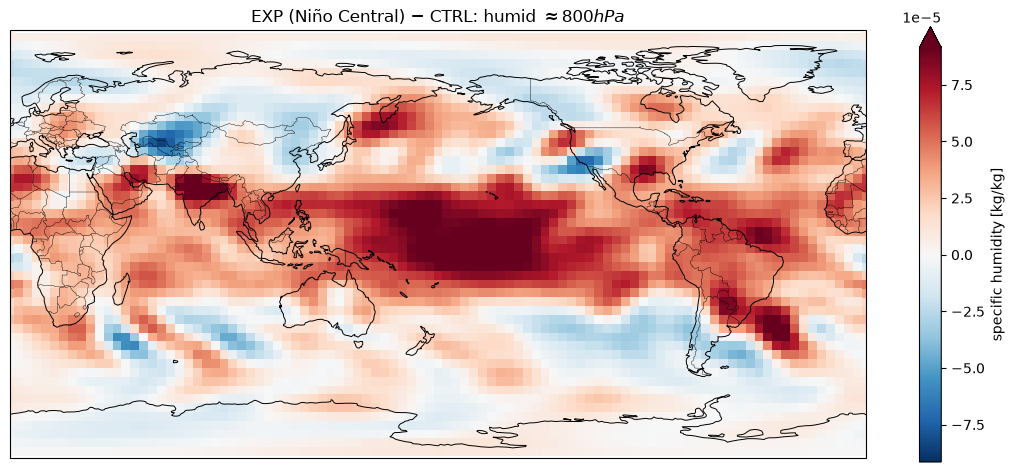

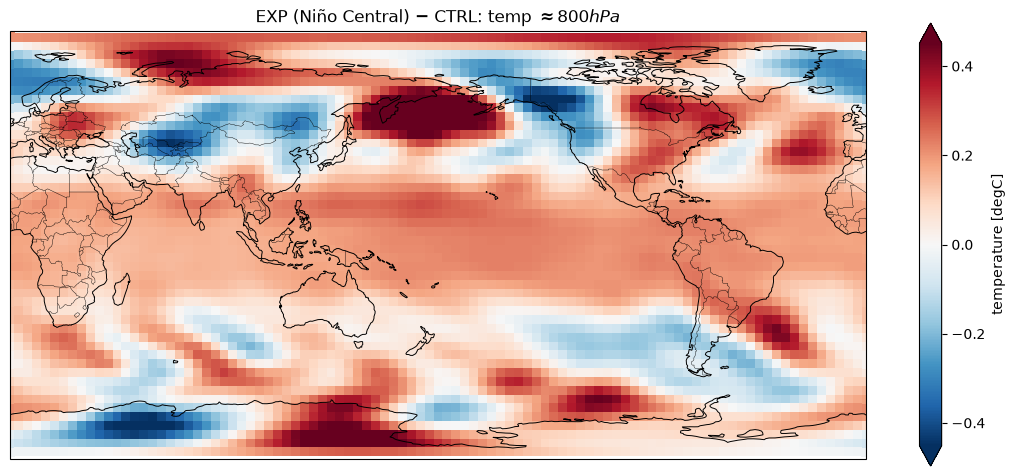

In [27]:
for var in ["humid", "temp"]:

    ctrl_mean = tctrl[var].sel(
        layer=LOW_SIGMA
    ).mean("time")

    exp_mean = texp[var].sel(
        layer=LOW_SIGMA
    ).mean("time")

    diff = (
        exp_mean
        -
        ctrl_mean
        )

    plot_map(
        diff,
        title=(
            f"EXP (Niño Central) − CTRL: {var} "
            r"$\approx 800 hPa$"
        ),
        symmetric=True,
        cmap="RdBu_r"
    )

# Comparación regional

In [28]:
# Definimos las regiones
REGIONES = {
    "Pacífico occidental": ((-5, 5), (120, 170)),
    "Pacífico central": ((-5, 5), (170, 220)),
    "Pacífico oriental": ((-5, 5), (220, 280)),
}

rows = []

dp = (
    rain_rate(texp).mean("time")
    -
    rain_rate(tctrl).mean("time")
)

for region, (lat_bounds, lon_bounds) in REGIONES.items():

    value = float(
        area_prom(
            dp,
            lat_bounds=lat_bounds,
            lon_bounds=lon_bounds
        )
    )

    rows.append({
        "experimento": 'EXP (Niño Central)',
        "region": region,
        "P_anom_mm_hr": value
    })


regional_precip = pd.DataFrame(rows)
regional_precip

,experimento,region,P_anom_mm_hr
0,EXP (Niño Central),Pacífico occidental,-0.001652
1,EXP (Niño Central),Pacífico central,0.012044
2,EXP (Niño Central),Pacífico oriental,-0.001350


# Productos esperados de la práctica 03 - ENSO

Llevar a cabo en anális desarrollado en este notebook para cada una de las realizaciones mencionadas al incio:

- **CONTROL** 
- **NINO_CENTRAL** 
- **NINO_EAST** 
- **NINA**

Gráficas mínimas esperadas: 

1. Mapa de $SST'$.
2. Mapa de $P'$.
3. Viento anómalo en niveles bajo/alto.
4. Divergencia comparativa en panel y anomalía en niveles alto/bajo.
5. Corte ecuatorial longitud–nivel de  'u'.
6. Comparaciones de los experimentos Niño Central, Niño Este, Niña con el CTRL
7. Comparación Niño Central vs Niño Este
8. Comparación El Niño vs. La Niña.
   
En la sección de discusión, se espera una argumentación alrededor de la retroalimentación de Bjerknes, por ej. que parte está representada y cuál falta.

## Pregunta final

$$
{\textbf{¿Cómo cambia la respuesta atmosférica 
 al cambiar posición y signo de SST'?}}
$$

# Algunos comentarios de las simulaciones

No debe confundirse el **tiempo de ajuste atmosférico** con la **longitud necesaria para estimar una climatología robusta**. El ajuste atmosférico ocurre en días–meses; los años adicionales sirven principalmente para reducir el ruido de muestreo.

La longitud temporal de la simulación fue de:


$$
\boxed{2\ {\rm años\ de\ spin\text{-}up}+50\ {\rm años\ de\ análisis}}
$$


es una estrategia razonable. Esto se puede confirmar al inspeccionar las series tiempo mostradas al inicio del análisis.

Integraciones de periodos mayores de tiempo pueden reducir todavía más el ruido de muestreo, pero no son estrictamente necesarias.